In [1]:
!pip install gym_bandits numpy==1.23.5

In [3]:
import gym
import gym_bandits
import numpy as np

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [4]:
env = gym.make('MultiarmedBandits-v0')

/usr/local/lib/python3.12/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.12/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(


In [5]:
print(env.observation_space)

Discrete(1)


In [6]:
print(env.action_space)

Discrete(10)


Estimated Q-values for each arm: [ 0.01  0.22  0.1   0.27 -0.07 -0.2  -0.14 -0.16  0.22 -0.48]
Number of times each arm was selected: [  7  56   2 294  69  10   7  10  40   5]
Average reward over all epsidoes: 0.176


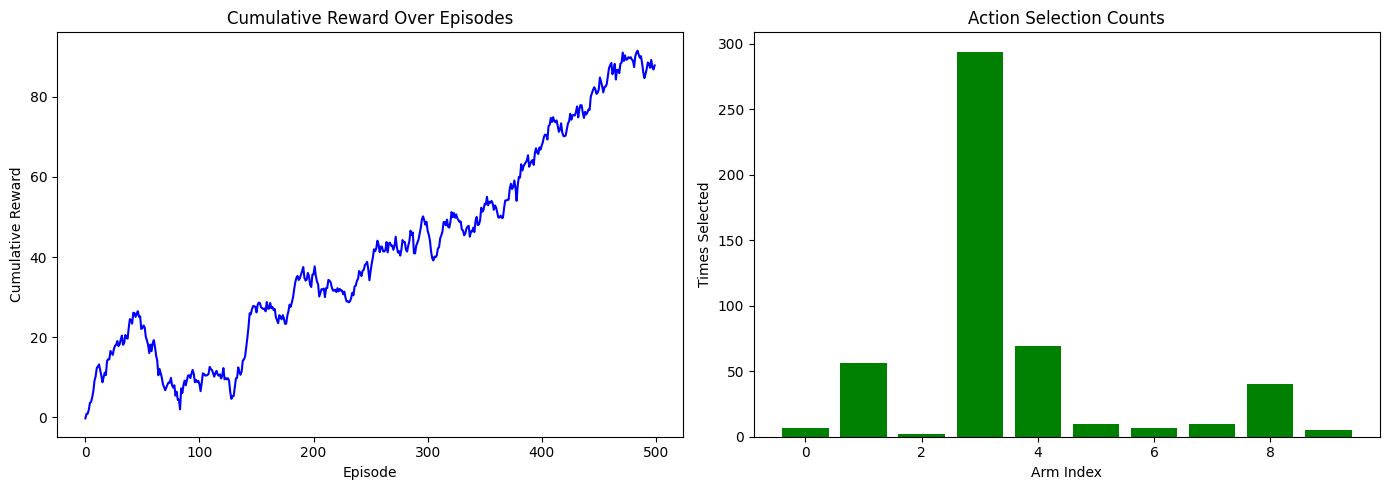

In [9]:
import warnings
import matplotlib.pyplot as plt

n_arms = env.action_space.n
num_episodes = 500
epsilon = 0.1
q_values = np.zeros(n_arms)
counts = np.zeros(n_arms)
reward_sums = np.zeros(n_arms)

all_rewards = []
action_history =[]

warnings.filterwarnings("ignore", category=DeprecationWarning)

for episode in range(num_episodes):
  env.reset()

  if np.random.rand() < epsilon:
    action = env.action_space.sample()
  else:
    action = np.argmax(q_values)

  observation, reward, done, info = env.step(action)
  counts[action] += 1
  reward_sums[action] += reward
  q_values[action] = reward_sums[action] / counts[action]

  all_rewards.append(reward)
  action_history.append(action)
env.close()

print("Estimated Q-values for each arm:" , np.round(q_values, 2))
print("Number of times each arm was selected:", counts.astype(int))
print("Average reward over all epsidoes:", round(np.mean(all_rewards), 3))

plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(np.cumsum(all_rewards), color= 'blue')
plt.title("Cumulative Reward Over Episodes")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")

plt.subplot(1,2,2)
plt.bar(np.arange(n_arms), counts, color= 'green')
plt.title("Action Selection Counts")
plt.xlabel("Arm Index")
plt.ylabel("Times Selected")

plt.tight_layout()
plt.show()